In [1]:
pip install requests beautifulsoup4 numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


Number of event folders found: 929

Number of events with valid timescales: 929

Timescale statistics:
Mean: 42.226083961248655 days
Median: 27.218 days
Standard deviation: 63.13159010687474 days
Minimum: 0.371 days
Maximum: 1403.596 days


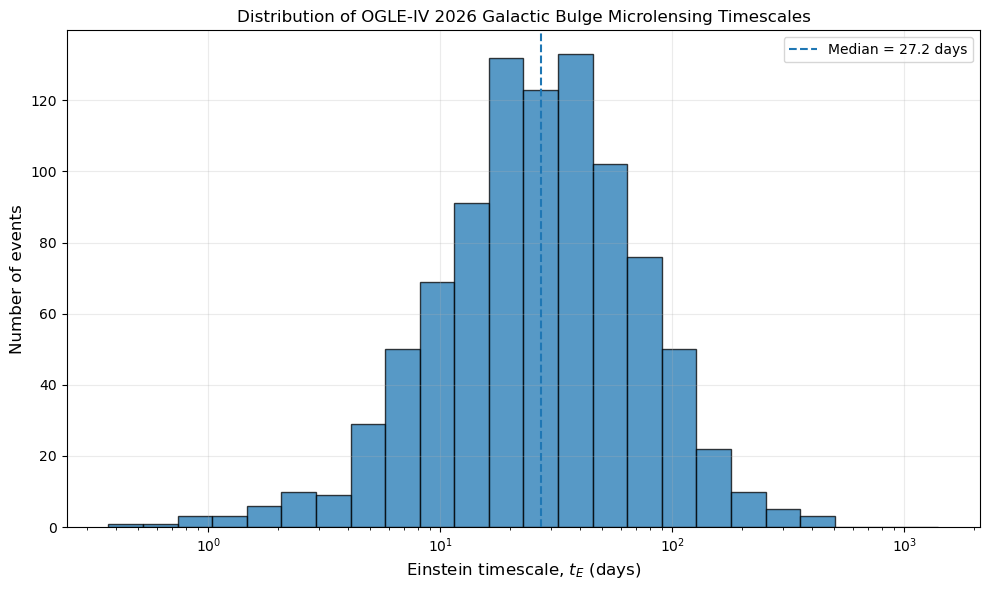


Saved:
OGLE_2026_tE_distribution.png
OGLE_2026_tE_values.csv


In [2]:

import requests
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.pyplot as plt
import re
from urllib.parse import urljoin
import pandas as pd


base_url = "https://www.astrouw.edu.pl/ogle/ogle4/ews/2026/"

response = requests.get(base_url)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

# Find all individual event directories
event_folders = []

for link in soup.find_all("a"):
    href = link.get("href", "")

    if re.fullmatch(r"blg-\d{4}/", href):
        event_folders.append(href)

print("Number of event folders found:", len(event_folders))


##Download

event_names = []
tE_values = []
tE_errors = []

for folder in event_folders:

    event_url = urljoin(base_url, folder)
    params_url = urljoin(event_url, "params.dat")

    try:
        data = requests.get(params_url, timeout=15)
        data.raise_for_status()


        match = re.search(
            r"^\s*tau\s+([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
            r"\s+([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)",
            data.text,
            re.MULTILINE
        )

        if match:

            tE = float(match.group(1))
            error = float(match.group(2))

            # Keep positive, finite timescales
            if np.isfinite(tE) and tE > 0:

                event_names.append(folder.strip("/"))
                tE_values.append(tE)
                tE_errors.append(error)

    except requests.RequestException:
        # Some event folders may not contain params.dat
        continue


# Convert to numpy arrays
tE_values = np.array(tE_values)
tE_errors = np.array(tE_errors)

print("\nNumber of events with valid timescales:", len(tE_values))



print("\nTimescale statistics:")
print("Mean:", np.mean(tE_values), "days")
print("Median:", np.median(tE_values), "days")
print("Standard deviation:", np.std(tE_values), "days")
print("Minimum:", np.min(tE_values), "days")
print("Maximum:", np.max(tE_values), "days")



##Plot
plt.figure(figsize=(10, 6))


bins = np.logspace(
    np.log10(tE_values.min()),
    np.log10(tE_values.max()),
    25
)

plt.hist(
    tE_values,
    bins=bins,
    edgecolor="black",
    alpha=0.75
)

plt.xscale("log")

plt.xlabel(r"Einstein timescale, $t_E$ (days)", fontsize=12)
plt.ylabel("Number of events", fontsize=12)

plt.title(
    "Distribution of OGLE-IV 2026 Galactic Bulge "
    "Microlensing Timescales"
)

plt.axvline(
    np.median(tE_values),
    linestyle="--",
    label=f"Median = {np.median(tE_values):.1f} days"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("OGLE_2026_tE_distribution.png", dpi=300)
plt.show()



results = pd.DataFrame({
    "Event": event_names,
    "tE_days": tE_values,
    "tE_error_days": tE_errors
})

results.to_csv("OGLE_2026_tE_values.csv", index=False)

print("\nSaved:")
print("OGLE_2026_tE_distribution.png")
print("OGLE_2026_tE_values.csv")


In [3]:
# Count events with tE less than 1 day
short_events = np.sum(tE_values < 1)

# Calculate percentage
percentage = (short_events / len(tE_values)) * 100

print("Events with tE < 1 day:", short_events)
print(f"Percentage of events: {percentage:.2f}%")

Events with tE < 1 day: 4
Percentage of events: 0.43%


In [4]:
# Find event IDs with tE < 1 day
short_event_data = results[results["tE_days"] < 1]

print(short_event_data)

        Event  tE_days  tE_error_days
732  blg-0733    0.978          0.056
814  blg-0815    0.570          0.013
825  blg-0826    0.937          0.037
842  blg-0843    0.371          0.008
